In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("Versi TensorFlow:", tf.__version__)
print("Daftar GPU yang aktif:", tf.config.list_physical_devices('GPU'))

Versi TensorFlow: 2.21.0
Daftar GPU yang aktif: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import shutil
from pathlib import Path

!rm -rf EuroSAT.zip 2750 dataset_deforestasi

print("Mengunduh dataset EuroSAT (~89 MB) dari server cepat...")
!curl -L "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/EuroSAT.zip" -o EuroSAT.zip

ukuran_mb = os.path.getsize("EuroSAT.zip") / (1024 * 1024)
print(f"Ukuran file terunduh: {ukuran_mb:.2f} MB")

print("Sedang mengekstrak file zip...")
!unzip -q -o EuroSAT.zip

forest_dirs = [p for p in Path('.').rglob('Forest') if p.is_dir() and 'dataset_deforestasi' not in str(p)]
source_dir = forest_dirs[0].parent

target_dir = Path('dataset_deforestasi')
target_dir.mkdir(exist_ok=True)

selected_classes = [
    'Forest',
    'AnnualCrop',
    'PermanentCrop',
    'Highway',
    'Industrial'
]

print("\nMenyiapkan dataset pemicu deforestasi:")
total_citra = 0
for cls in selected_classes:
    src_cls_path = source_dir / cls
    dst_cls_path = target_dir / cls
    if not dst_cls_path.exists():
        shutil.copytree(src_cls_path, dst_cls_path)
    jumlah_foto = len(list(dst_cls_path.glob('*.jpg')))
    total_citra += jumlah_foto
    print(f"- Kelas {cls:15s}: {jumlah_foto} foto satelit")

print(f"\nTotal keseluruhan: {total_citra} citra satelit siap digunakan")

Mengunduh dataset EuroSAT (~89 MB) dari server cepat...
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   984  100   984    0     0   3681      0 --:--:-- --:--:-- --:--:--  3685
100 89.9M  100 89.9M    0     0  50.4M      0  0:00:01  0:00:01 --:--:-- 72.3M
Ukuran file terunduh: 89.91 MB
Sedang mengekstrak file zip...

Menyiapkan dataset pemicu deforestasi:
- Kelas Forest         : 3000 foto satelit
- Kelas AnnualCrop     : 3000 foto satelit
- Kelas PermanentCrop  : 2500 foto satelit
- Kelas Highway        : 2500 foto satelit
- Kelas Industrial     : 2500 foto satelit

Total keseluruhan: 13500 citra satelit siap digunakan!


Membagi dataset menjadi Data Latih (80%) dan Data Uji (20%)...
Found 13500 files belonging to 5 classes.
Using 10800 files for training.
Found 13500 files belonging to 5 classes.
Using 2700 files for validation.


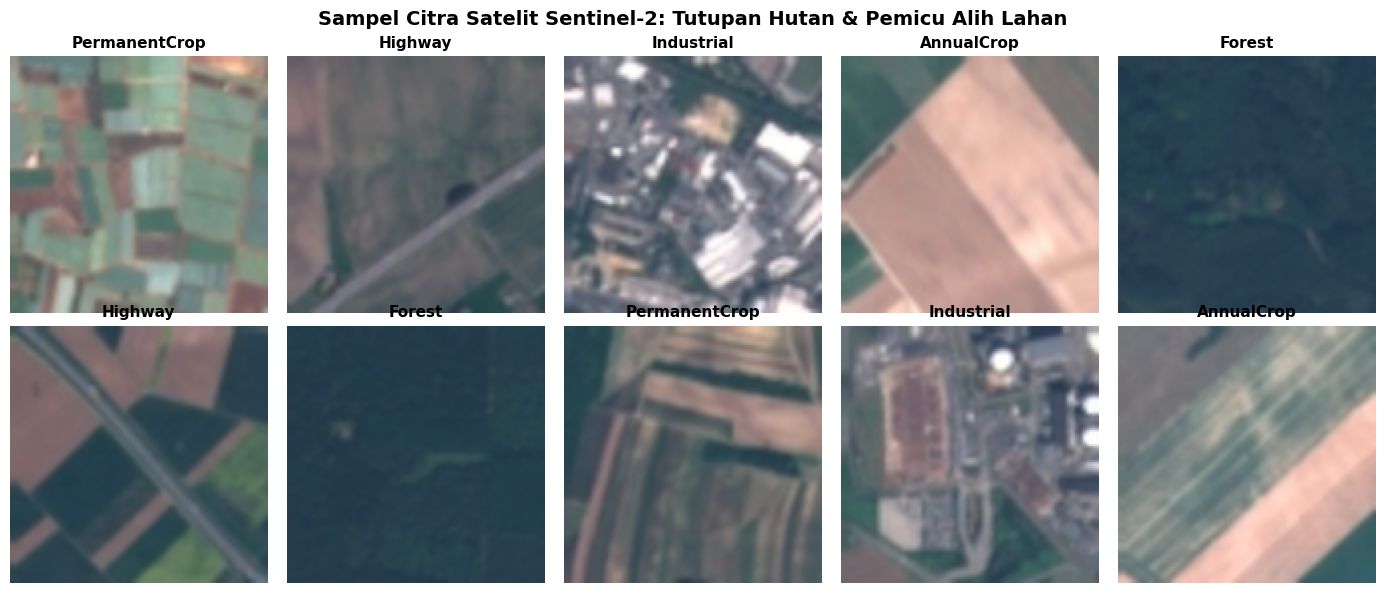


Data siap digunakan untuk melatih model AI!


In [3]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

selected_classes = [
    'Forest',
    'AnnualCrop',
    'PermanentCrop',
    'Highway',
    'Industrial'
]

print("Membagi dataset menjadi Data Latih (80%) dan Data Uji (20%)...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset_deforestasi',
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=selected_classes
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset_deforestasi',
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=selected_classes
)

plt.figure(figsize=(14, 6))
for images, labels in train_ds.take(1):
    for i in range(10):
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(selected_classes[labels[i]], fontsize=11, fontweight='bold')
        plt.axis("off")

plt.suptitle("Sampel Citra Satelit Sentinel-2: Tutupan Hutan & Pemicu Alih Lahan", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("sample_satellite_images.png", dpi=150)
plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
print("\nData siap digunakan untuk melatih model AI")

In [4]:
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
], name="Augmentasi_Citra_Satelit")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(128, 128, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(5, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs, name="Model_Deforestasi_MobileNetV2")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

print("\nMemulai proses pelatihan (Training) Model AI...")
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)
print("\nPelatihan selesai!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "Model_Deforestasi_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Augmentasi_Citra_Satelit        │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Memulai proses pelatihan (Training) Model AI...
Epoch 1/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.8968 - loss: 0.2857 - val_accuracy: 0.9522 - val_loss: 0.1324
Epoch 2/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9463 - loss: 0.1481 - val_accuracy: 0.9593 - val_loss: 0.1146
Epoch 3/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9510 - loss: 0.1369 - val_accuracy: 0.9633 - val_loss: 0.1138
Epoch 4/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9571 - loss: 0.1205 - val_accuracy: 0.9637 - val_loss: 0.0977
Epoch 5/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9569 - loss: 0.1166 - val_accuracy: 0.9648 - val_loss: 0.1021
Epoch 6/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9585 - loss: 0.1219 - val_accuracy: 0.9633 - val_loss: 0.1099
Epoch 7/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9594 - loss: 0.1187 - val_accuracy: 0.9644 - val_loss: 0.0975
Epoch 8/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26m

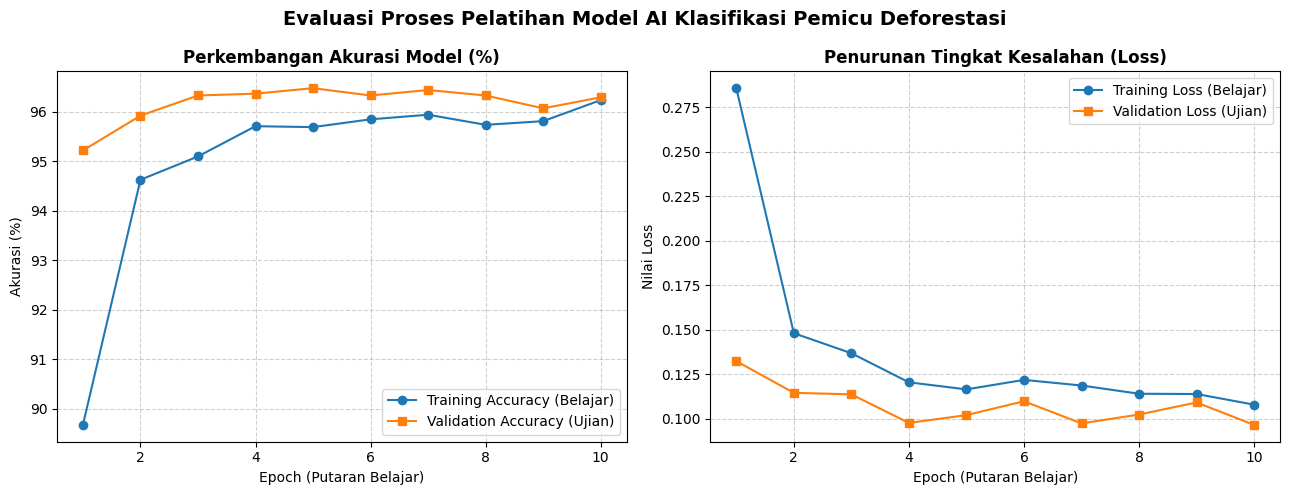

Akurasi Ujian Tertinggi (Validation Accuracy): 96.48%


In [5]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, [a * 100 for a in acc], 'o-', label='Training Accuracy (Belajar)')
plt.plot(epochs_range, [v * 100 for v in val_acc], 's-', label='Validation Accuracy (Ujian)')
plt.title('Perkembangan Akurasi Model (%)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch (Putaran Belajar)')
plt.ylabel('Akurasi (%)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'o-', label='Training Loss (Belajar)')
plt.plot(epochs_range, val_loss, 's-', label='Validation Loss (Ujian)')
plt.title('Penurunan Tingkat Kesalahan (Loss)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch (Putaran Belajar)')
plt.ylabel('Nilai Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Evaluasi Proses Pelatihan Model AI Klasifikasi Pemicu Deforestasi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('training_history.png', dpi=150)
plt.show()

print(f"Akurasi Ujian Tertinggi (Validation Accuracy): {max(val_acc)*100:.2f}%")

Sedang menguji model AI pada 2.700 foto citra satelit...


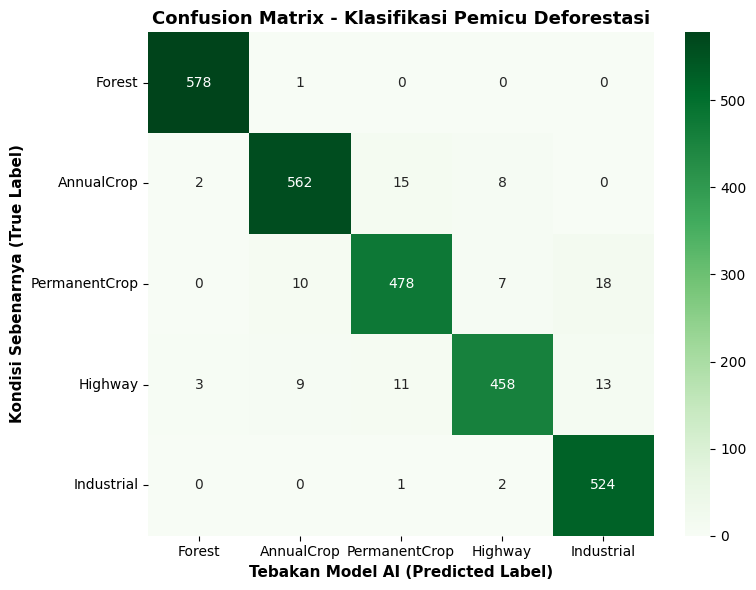


=== LAPORAN PERFORMA MODEL AI PER KELAS (CLASSIFICATION REPORT) ===

               precision    recall  f1-score   support

       Forest     0.9914    0.9983    0.9948       579
   AnnualCrop     0.9656    0.9574    0.9615       587
PermanentCrop     0.9465    0.9318    0.9391       513
      Highway     0.9642    0.9271    0.9453       494
   Industrial     0.9441    0.9943    0.9686       527

     accuracy                         0.9630      2700
    macro avg     0.9624    0.9618    0.9619      2700
 weighted avg     0.9631    0.9630    0.9628      2700



In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = []
y_pred = []
sample_data = []

print("Sedang menguji model AI pada 2.700 foto citra satelit...")
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

    if len(sample_data) < 10:
        for i in range(len(images)):
            if len(sample_data) < 10:
                img = images[i].numpy().astype("uint8")
                true_idx = labels[i].numpy()
                pred_idx = np.argmax(preds[i])
                conf = np.max(preds[i]) * 100
                sample_data.append((img, true_idx, pred_idx, conf))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=selected_classes,
    yticklabels=selected_classes
)
plt.title('Confusion Matrix - Klasifikasi Pemicu Deforestasi', fontsize=13, fontweight='bold')
plt.xlabel('Tebakan Model AI (Predicted Label)', fontsize=11, fontweight='bold')
plt.ylabel('Kondisi Sebenarnya (True Label)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print("\n=== LAPORAN PERFORMA MODEL AI PER KELAS (CLASSIFICATION REPORT) ===\n")
print(classification_report(y_true, y_pred, target_names=selected_classes, digits=4))

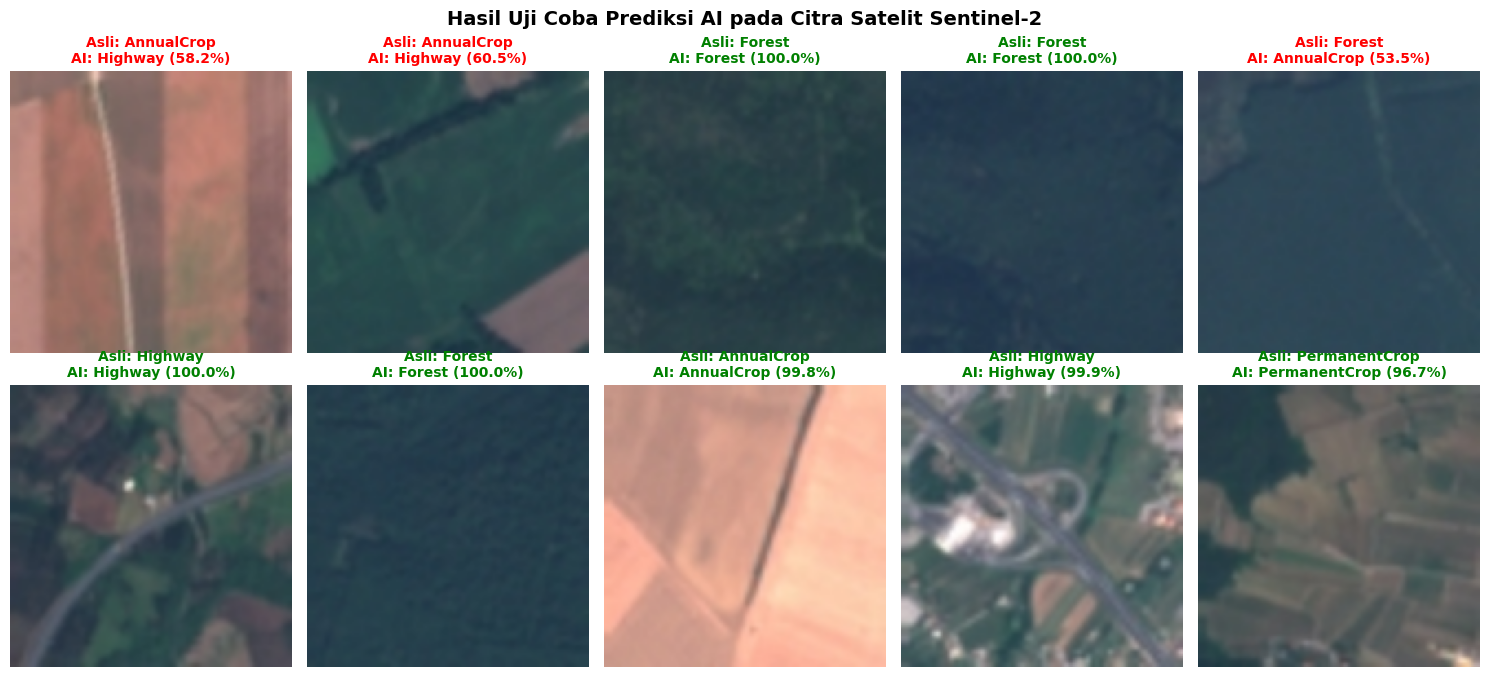

Sedang mengunduh 4 gambar grafik ke komputer Anda...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

plt.figure(figsize=(15, 7))
for i, (img, true_idx, pred_idx, conf) in enumerate(sample_data):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    true_name = selected_classes[true_idx]
    pred_name = selected_classes[pred_idx]

    warna = "green" if true_idx == pred_idx else "red"
    plt.title(f"Asli: {true_name}\nAI: {pred_name} ({conf:.1f}%)", color=warna, fontsize=10, fontweight='bold')
    plt.axis("off")

plt.suptitle("Hasil Uji Coba Prediksi AI pada Citra Satelit Sentinel-2", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("prediction_results.png", dpi=150)
plt.show()

daftar_gambar = [
    "sample_satellite_images.png",
    "training_history.png",
    "confusion_matrix.png",
    "prediction_results.png"
]

print("Sedang mengunduh 4 gambar grafik ke komputer Anda...")
for nama_file in daftar_gambar:
    files.download(nama_file)